# B2B SaaS Subscription Revenue Analytics

**Dataset:** RavenStack (Kaggle) - accounts, subscriptions, churn_events, feature_usage, support_tickets
**Environment:** SQLite (in-memory) + pandas

**Contents**
1. Setup
2. Data Quality Checks
3. MRR Foundation (views)
4. Core Revenue Metrics: MRR, Waterfall, Growth Rate, ARR, Visualizations
5. Churn Analysis
6. Cohort Retention
7. Segmentation and LTV

## 1. Setup

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
conn = sqlite3.connect(':memory:')

files = {
    'accounts': 'data/ravenstack_accounts.csv',
    'churn_events': 'data/ravenstack_churn_events.csv',
    'feature_usage': 'data/ravenstack_feature_usage.csv',
    'subscriptions': 'data/ravenstack_subscriptions.csv',
    'support_tickets': 'data/ravenstack_support_tickets.csv'
}
for table_name, file_path in files.items():
    t_df = pd.read_csv(file_path)
    t_df.to_sql(table_name, conn, index=False, if_exists='replace')
    print(f"Table '{table_name}' loaded ({len(t_df):,} rows).")

Table 'accounts' loaded (500 rows).
Table 'churn_events' loaded (600 rows).
Table 'feature_usage' loaded (25,000 rows).
Table 'subscriptions' loaded (5,000 rows).
Table 'support_tickets' loaded (2,000 rows).


In [3]:
def run_query(query):
    return pd.read_sql_query(query, conn)


def run_script(script):
    conn.executescript(script)

## 2. Data Quality Checks

Each check states the question it answers.

### 2.1 Subscriptions overview
Row counts, date ranges and trial volume.

In [4]:
run_query("""
select
count(*) as row_count,
count(distinct account_id) as unique_accounts,
min(start_date) as first_start,
max(start_date) as last_start,
min(end_date) as first_end,
max(end_date) as last_end,
sum(case when is_trial = 1 then 1 else 0 end) as trial_count,
sum(case when is_trial = 1 then mrr_amount else 0 end) as trial_mrr
from subscriptions
""")

,row_count,unique_accounts,first_start,last_start,first_end,last_end,trial_count,trial_mrr
0,5000,500,2023-01-09,2024-12-31,2023-04-05,2024-12-31,778,0


### 2.2 Trial rows and MRR
Do all zero-MRR rows belong to trials?

In [5]:
run_query("""
select
is_trial,
count(*) as row_count
from subscriptions
where mrr_amount = 0
group by 1
""")

,is_trial,row_count
0,1,778


### 2.3 End date vs. churn flag
How are `churn_flag` and a missing `end_date` related?

In [6]:
run_query("""
select
churn_flag,
case when end_date is null then 'empty' else 'filled' end as end_date_status,
count(*) as row_count
from subscriptions
group by 1, 2
order by 1, 2
""")

,churn_flag,end_date_status,row_count
0,0,empty,4514
1,1,filled,486


### 2.4 Accounts with no active paid subscription
Accounts where every paid subscription has an end date.

In [7]:
run_query("""
with flag as (
select
account_id,
sum(case when end_date is null and is_trial = 0 then 1 else 0 end) as active_count
from subscriptions
group by 1)

select
count(*) as passive_accs
from flag
where active_count = 0
""")

,passive_accs
0,0


### 2.5 Churn events table
Structure, volume and events per account.

In [8]:
run_query("""pragma table_info(churn_events)""")

,cid,name,type,notnull,dflt_value,pk
0,0,churn_event_id,TEXT,0,None,0
1,1,account_id,TEXT,0,None,0
2,2,churn_date,TEXT,0,None,0
3,3,reason_code,TEXT,0,None,0
4,4,refund_amount_usd,REAL,0,None,0
5,5,preceding_upgrade_flag,INTEGER,0,None,0
6,6,preceding_downgrade_flag,INTEGER,0,None,0
7,7,is_reactivation,INTEGER,0,None,0
8,8,feedback_text,TEXT,0,None,0


In [9]:
run_query("""
select * from churn_events
limit 5
""")

,churn_event_id,account_id,churn_date,reason_code,refund_amount_usd,preceding_upgrade_flag,preceding_downgrade_flag,is_reactivation,feedback_text
0,C-816288,A-c37cab,2024-10-27,pricing,4.03,0,0,0,switched to competitor
1,C-5a81e7,A-37f969,2024-06-25,support,96.45,1,0,0,None
2,C-a174be,A-b07346,2024-11-12,budget,0.00,0,0,0,missing features
3,C-accb39,A-1e50e0,2023-11-01,budget,54.94,0,0,0,switched to competitor
4,C-92f889,A-956988,2024-12-30,unknown,0.00,0,1,1,too expensive


In [10]:
run_query("""
select
count(*) as row_count,
count(distinct account_id) as unique_accounts,
min(churn_date) as first_churn,
max(churn_date) as last_churn
from churn_events
""")

,row_count,unique_accounts,first_churn,last_churn
0,600,352,2023-01-25,2024-12-31


In [11]:
run_query("""
with accs as (
select
account_id,
count(*) as acc_count
from churn_events
group by 1)

select
acc_count,
count(account_id) as user_count
from accs
group by 1
order by 1 desc
""")

,acc_count,user_count
0,5,2
1,4,10
2,3,47
3,2,116
4,1,177


### 2.6 Churn source consistency
Do `churn_events` and `subscriptions.churn_flag` identify the same accounts?

In [12]:
run_query("""
with flags as (
select
a.account_id,
case when a.account_id in (select account_id from churn_events) then 1 else 0 end as in_events,
case when a.account_id in (select account_id from subscriptions where churn_flag = 1) then 1 else 0 end as in_flag
from accounts a
)
select
in_events,
in_flag,
count(*) as account_count
from flags
group by 1, 2
order by 1, 2
""")

,in_events,in_flag,account_count
0,0,0,63
1,0,1,85
2,1,0,125
3,1,1,227


### 2.7 Single-account sanity check
Subscription history of one sample account.

In [13]:
run_query("""
select
start_date,
end_date,
plan_tier,
mrr_amount
from subscriptions
where account_id = 'A-3c1a3f'
order by 1 asc
""")

,start_date,end_date,plan_tier,mrr_amount
0,2023-08-31,None,Basic,0
1,2023-12-18,None,Basic,0
2,2023-12-23,2024-04-12,Enterprise,2786
3,2023-12-28,None,Enterprise,5771
4,2023-12-29,None,Pro,0
5,2024-03-25,None,Basic,76
6,2024-04-28,None,Enterprise,398
7,2024-05-06,2024-11-25,Pro,931
8,2024-09-30,None,Enterprise,597
9,2024-10-07,None,Pro,4018


### 2.8 Decisions

- Account-level monthly MRR is derived from `subscriptions`.
- Churn = account MRR drops from positive to 0. Reactivation is a separate row.
- `churn_events` is used for churn reason analysis only (the two sources agree on just 227 of 500 accounts).
- A subscription whose `end_date` is the first day of a month counts as active in that month.
- Trial rows have MRR 0 and do not affect revenue metrics.

## 3. MRR Foundation

The account x month MRR logic is defined once as three SQLite views. All later metrics read from them.

| View | Grain | Purpose |
|---|---|---|
| `account_month_mrr` | account x month | MRR and previous-month MRR |
| `mrr_movements` | account x month | Movement type (new, expansion, contraction, churned, unchanged) |
| `monthly_mrr` | month | Total MRR and waterfall components |

In [14]:
run_script("""
drop view if exists account_month_mrr;
drop view if exists mrr_movements;
drop view if exists monthly_mrr;

create view account_month_mrr as
with recursive months as (
    select '2023-01-01' as month_start
    union all
    select date(month_start, '+1 month')
    from months
    where month_start < '2024-12-01'
),
account_grid as (
    select
        m.month_start,
        a.account_id
    from months m
    cross join accounts a
),
account_mrr_by_month as (
    select
        g.month_start,
        g.account_id,
        coalesce(sum(s.mrr_amount), 0) as account_mrr
    from account_grid g
    left join subscriptions s
        on s.account_id = g.account_id
        and s.start_date <= date(g.month_start, '+1 month', '-1 day')
        and (s.end_date is null or s.end_date >= g.month_start)
    group by g.month_start, g.account_id
)
select
    month_start,
    account_id,
    account_mrr,
    lag(account_mrr, 1, 0) over (partition by account_id order by month_start) as prev_mrr
from account_mrr_by_month;

create view mrr_movements as
select
    *,
    case
        when prev_mrr = 0 and account_mrr > 0 then 'new'
        when prev_mrr > 0 and account_mrr > prev_mrr then 'expansion'
        when prev_mrr > 0 and account_mrr > 0 and account_mrr < prev_mrr then 'contraction'
        when prev_mrr > 0 and account_mrr = 0 then 'churned'
        else 'unchanged'
    end as movement_type,
    account_mrr - prev_mrr as mrr_change
from account_month_mrr;

create view monthly_mrr as
select
    month_start,
    sum(account_mrr) as total_mrr,
    sum(case when movement_type = 'new' then mrr_change else 0 end) as new_mrr,
    sum(case when movement_type = 'expansion' then mrr_change else 0 end) as expansion_mrr,
    sum(case when movement_type = 'contraction' then mrr_change else 0 end) as contraction_mrr,
    sum(case when movement_type = 'churned' then mrr_change else 0 end) as churned_mrr,
    sum(mrr_change) as net_change
from mrr_movements
group by month_start;
""")

## 4. Core Revenue Metrics

### 4.1 MRR snapshot: 2024-06
Expected: total MRR 3,854,007 from 1,470 paid subscriptions (avg 2,621.77).

In [15]:
run_query("""
select
sum(mrr_amount) as mrr_sum
from subscriptions
where start_date <= '2024-06-30' and
(end_date is null or end_date >= '2024-06-01')
""")

,mrr_sum
0,3854007


In [16]:
run_query("""
select
count(*) as active_subscriptions,
sum(case when is_trial = 0 then 1 else 0 end) as paid_subscriptions,
round(1.0 * sum(mrr_amount) / sum(case when is_trial = 0 then 1 else 0 end), 2) as avg_mrr
from subscriptions
where start_date <= '2024-06-30' and
(end_date is null or end_date >= '2024-06-01')
""")

,active_subscriptions,paid_subscriptions,avg_mrr
0,1755,1470,2621.77


### 4.2 Monthly MRR and waterfall
Validation: components sum to net change (2024-06 = 514,222).

In [17]:
run_query("""
select * from monthly_mrr
order by month_start
""")

,month_start,total_mrr,new_mrr,expansion_mrr,contraction_mrr,churned_mrr,net_change
0,2023-01-01,4684,4684,0,0,0,4684
1,2023-02-01,15763,10148,931,0,0,11079
2,2023-03-01,41648,23168,2717,0,0,25885
3,2023-04-01,83436,28575,13213,0,0,41788
4,2023-05-01,169110,42466,43453,0,-245,85674
5,2023-06-01,244097,45649,29338,0,0,74987
6,2023-07-01,363343,60672,58574,0,0,119246
7,2023-08-01,528736,59214,106407,-228,0,165393
8,2023-09-01,644272,46013,69523,0,0,115536
9,2023-10-01,826790,30485,152033,0,0,182518


In [18]:
run_query("""
select
month_start,
new_mrr + expansion_mrr + contraction_mrr + churned_mrr - net_change as check_diff
from monthly_mrr
where check_diff <> 0
""")

,month_start,check_diff


**Findings**
- Only one account-level churn event (2023-12, -12,736). Losses come mostly from contraction.
- Expansion is the main growth driver.
- 2023-01 shows all MRR as `new` because the grid starts there.
- Decision: contraction stays as-is and is noted in the README.

### 4.3 Net MRR growth rate
Month-over-month growth. The first month is excluded (no previous MRR). Check: 2024-06 = 15.40%.

In [19]:
run_query("""
with growth as (
select
    month_start,
    total_mrr,
    lag(total_mrr) over (order by month_start) as prev_total_mrr,
    net_change
from monthly_mrr
)
select
    month_start,
    total_mrr,
    prev_total_mrr,
    net_change,
    round(100.0 * net_change / prev_total_mrr, 2) as growth_pct
from growth
where prev_total_mrr is not null
""")

,month_start,total_mrr,prev_total_mrr,net_change,growth_pct
0,2023-02-01,15763,4684,11079,236.53
1,2023-03-01,41648,15763,25885,164.21
2,2023-04-01,83436,41648,41788,100.34
3,2023-05-01,169110,83436,85674,102.68
4,2023-06-01,244097,169110,74987,44.34
5,2023-07-01,363343,244097,119246,48.85
6,2023-08-01,528736,363343,165393,45.52
7,2023-09-01,644272,528736,115536,21.85
8,2023-10-01,826790,644272,182518,28.33
9,2023-11-01,1038507,826790,211717,25.61


### 4.4 ARR and year-over-year growth
ARR = MRR x 12. YoY compares with the same month one year earlier. Check: 2024-06 ARR = 46,248,084, YoY = 1,478.88%.

In [20]:
run_query("""
with arr_calc as (
select
    month_start,
    total_mrr,
    total_mrr * 12 as arr
from monthly_mrr
),
arr_yoy as (
select
    month_start,
    total_mrr,
    arr,
    lag(arr, 12) over (order by month_start) as prev_year_arr
from arr_calc
)
select
    month_start,
    total_mrr,
    arr,
    prev_year_arr,
    round(100.0 * (arr - prev_year_arr) / prev_year_arr, 2) as yoy_pct
from arr_yoy
where prev_year_arr is not null
""")

,month_start,total_mrr,arr,prev_year_arr,yoy_pct
0,2024-01-01,1539046,18468552,56208,32757.51
1,2024-02-01,1888127,22657524,189156,11878.22
2,2024-03-01,2295694,27548328,499776,5412.14
3,2024-04-01,2722124,32665488,1001232,3162.53
4,2024-05-01,3339785,40077420,2029320,1874.92
5,2024-06-01,3854007,46248084,2929164,1478.88
6,2024-07-01,4541221,54494652,4360116,1149.84
7,2024-08-01,5161618,61939416,6344832,876.22
8,2024-09-01,6113247,73358964,7731264,848.86
9,2024-10-01,7208953,86507436,9921480,771.92


**Findings**
- Early-2024 YoY values are inflated by the small 2023 base.
- 2024-12 vs 2023-12 is the meaningful comparison.

### 4.5 MRR Visualizations

MRR waterfall (stacked bar) and MRR trend (line).

In [21]:
import os

os.makedirs('reports/assets', exist_ok=True)

In [22]:
df_waterfall = run_query("""
select
    *
    from monthly_mrr
    where month_start > '2023-01-01'
    order by month_start
""")

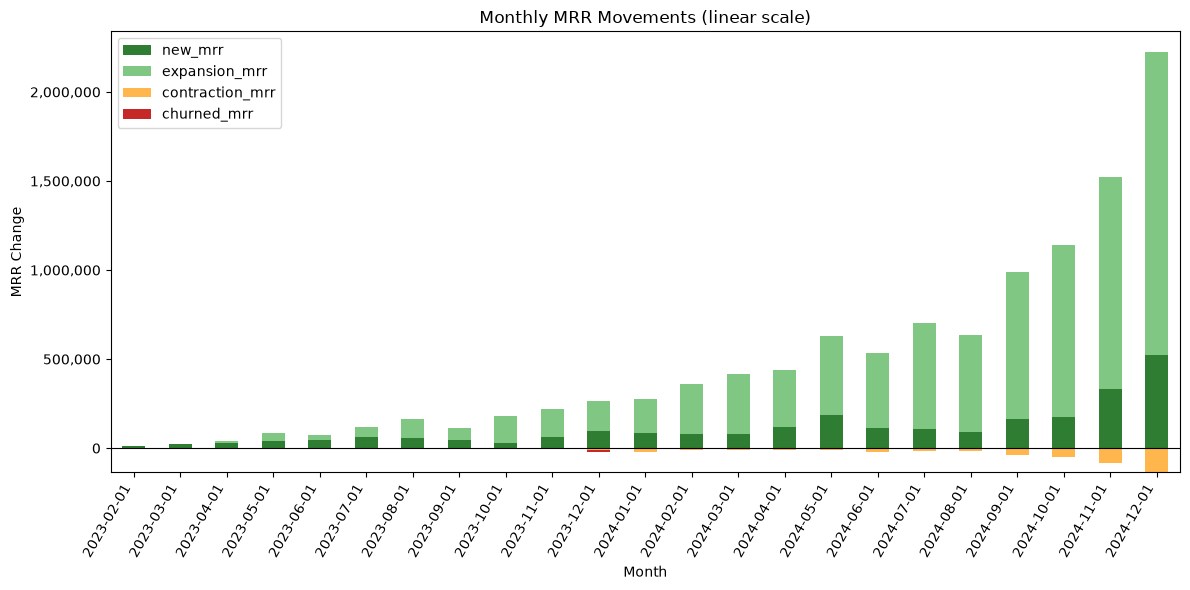

In [23]:
from matplotlib.ticker import FuncFormatter

df_plot = df_waterfall.set_index('month_start')
ax = df_plot.plot(kind='bar',
                  stacked=True,
                  y=['new_mrr', 'expansion_mrr', 'contraction_mrr', 'churned_mrr'],
                  color=['#2E7D32', '#81C784', '#FFB74D', '#C62828'],
                  figsize=(12, 6))
ax.set_title('Monthly MRR Movements (linear scale)')
ax.set_xlabel('Month')
ax.set_ylabel('MRR Change')
ax.axhline(0, color='black', linewidth=0.8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig('reports/assets/mrr_waterfall_linear.png', dpi=150, bbox_inches='tight')

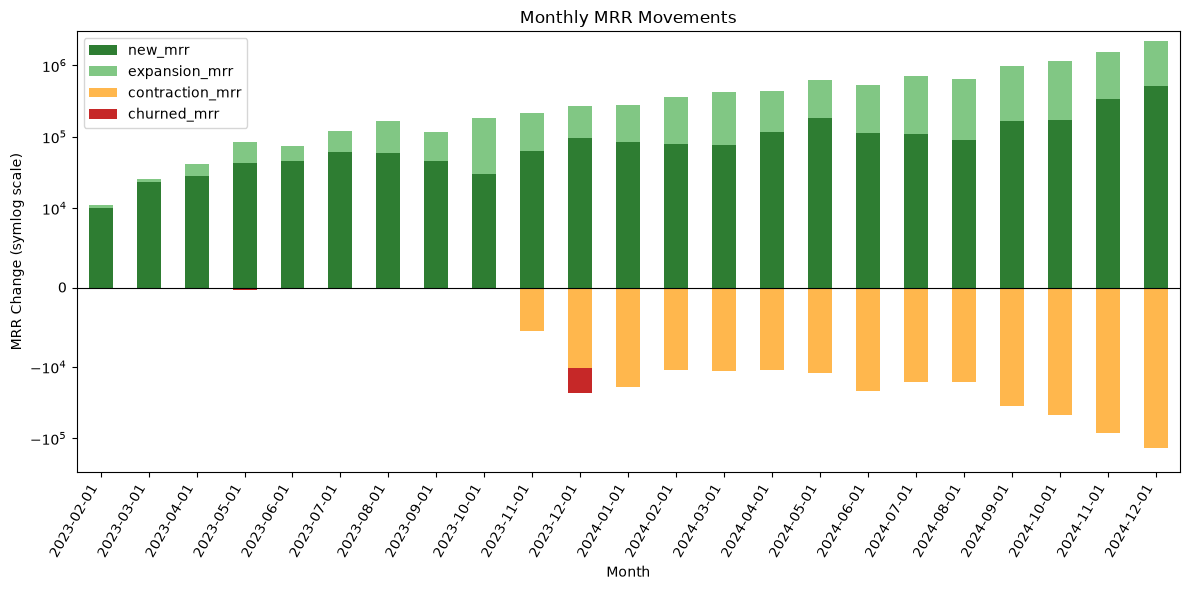

In [24]:
df_plot = df_waterfall.set_index('month_start')
ax = df_plot.plot(kind='bar',
          stacked=True,
          y=['new_mrr', 'expansion_mrr', 'contraction_mrr', 'churned_mrr'],
          color=['#2E7D32', '#81C784', '#FFB74D', '#C62828'],
         figsize=(12,6))
ax.set_yscale('symlog', linthresh=10000)
ax.set_title('Monthly MRR Movements')
ax.set_xlabel('Month')
ax.set_ylabel('MRR Change (symlog scale)')
ax.set_ylim(bottom=-3e5, top=3e6)
ax.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig('reports/assets/mrr_waterfall_symlog.png', dpi=150, bbox_inches='tight')

In [25]:
df_trend = run_query("""
select 
month_start,
total_mrr
from monthly_mrr
order by month_start
""")

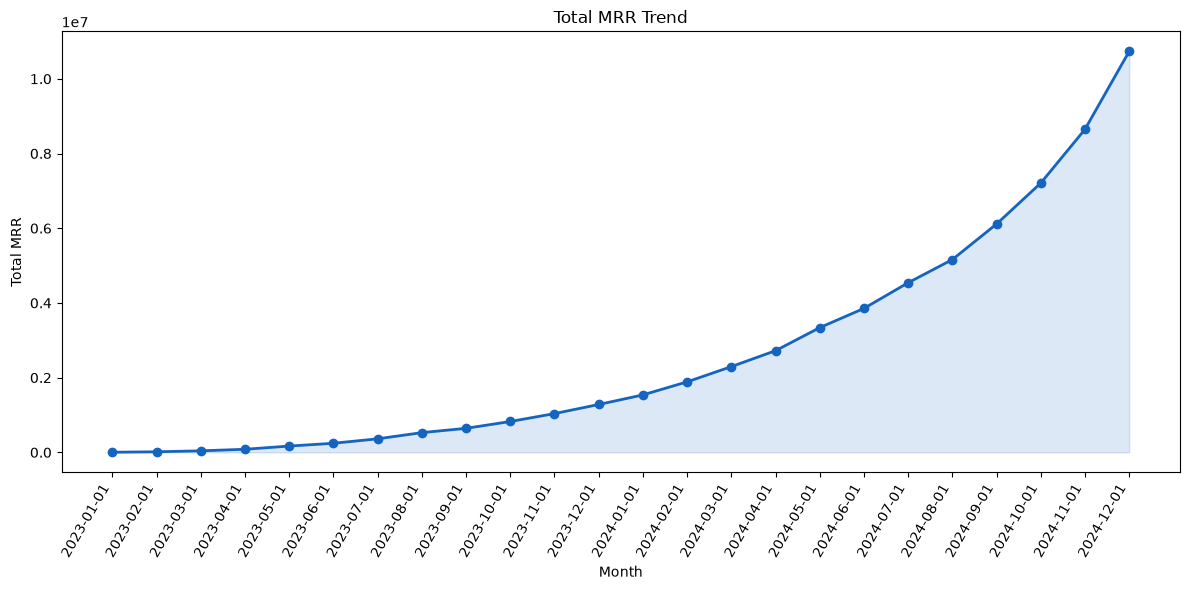

In [26]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_trend['month_start'], df_trend['total_mrr'],
        marker='o', linewidth=2, color='#1565C0')
ax.fill_between(df_trend['month_start'], df_trend['total_mrr'],
                alpha=0.15, color='#1565C0')
ax.set_title('Total MRR Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Total MRR')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig('reports/assets/mrr_trend.png', dpi=150, bbox_inches='tight')

## 5. Churn Analysis

### 5.1 Logo vs. Revenue Churn

In [27]:
run_query("""
with month_start_base as (
select
mrr_amount,
end_date
from subscriptions
where is_trial = 0
and start_date <= '2024-06-01'
and (end_date is null or end_date >= '2024-06-01')
)
select
count(*) as base_subscriptions,
sum(case when end_date < '2024-07-01' then 1 else 0 end) as lost_subscriptions,
sum(mrr_amount) as base_mrr,
sum(case when end_date < '2024-07-01' then mrr_amount else 0 end) as lost_mrr,
round(100.0 * sum(case when end_date < '2024-07-01' then 1 else 0 end) / count(*), 2) as logo_churn_pct,
round(100.0 * sum(case when end_date < '2024-07-01' then mrr_amount else 0 end) / sum(mrr_amount), 2) as revenue_churn_pct
from month_start_base
""")

,base_subscriptions,lost_subscriptions,base_mrr,lost_mrr,logo_churn_pct,revenue_churn_pct
0,1279,11,3343584,16796,0.86,0.5


### 5.2 Gross and Net Revenue Churn

In [28]:
df_churn_monthly = run_query("""
with recursive months as (
    select '2023-01-01' as month_start
    union all
    select date(month_start, '+1 month')
    from months
    where month_start < '2024-12-01'
)
select
m.month_start,
count(s.mrr_amount) as base_subscriptions,
sum(case when end_date < date(m.month_start, '+1 month') then 1 else 0 end) as lost_subscriptions,
sum(case when end_date < date(m.month_start, '+1 month') then mrr_amount else 0 end) as lost_mrr,
round(100.0 * sum(case when end_date < date(m.month_start, '+1 month') then 1 else 0 end) / count(s.mrr_amount), 2) as logo_churn_pct,
round(100.0 * sum(case when end_date < date(m.month_start, '+1 month') then mrr_amount else 0 end) / sum(mrr_amount), 2) as revenue_churn_pct
from months m
left join subscriptions s on
s.is_trial = 0 and s.start_date <= m.month_start
and (s.end_date is null or s.end_date >= m.month_start)
group by 1
""")

In [29]:
run_query("""
with mrr_mont_prev as (
select
*,
lag(total_mrr, 1 ) over (order by month_start) as prev_tot_mrr
from monthly_mrr
)

select
month_start,
round(-100.0 * (churned_mrr + contraction_mrr) / prev_tot_mrr , 2 ) as gross_churn_pct,
round(-100.0 * (churned_mrr + contraction_mrr + expansion_mrr) / prev_tot_mrr , 2 ) as net_churn_pct
from mrr_mont_prev
where prev_tot_mrr is not null
group by month_start
order by month_start
""")

,month_start,gross_churn_pct,net_churn_pct
0,2023-02-01,0.00,-19.88
1,2023-03-01,0.00,-17.24
2,2023-04-01,0.00,-31.73
3,2023-05-01,0.29,-51.79
4,2023-06-01,0.00,-17.35
5,2023-07-01,0.00,-24.00
6,2023-08-01,0.06,-29.22
7,2023-09-01,0.00,-13.15
8,2023-10-01,0.00,-23.60
9,2023-11-01,0.67,-17.94


### 5.3 Churn by Tenure

In [30]:
df_tenure = run_query("""
with td as (
select
account_id,
julianday(coalesce(end_date, '2024-12-31')) - julianday(start_date) as tenure_days,
case when end_date is null then 1 else 0 end as is_active
from subscriptions
where is_trial = 0),
buckets as (
select
count(*) as total_subs,
sum(case when is_active = 0 then 1 else 0 end) as ended_subs,
case when tenure_days < 90 then '1_0-3m'
     when tenure_days < 180 then '2_3-6m'
     when tenure_days < 270 then '3_6-9m' 
     else '4_9m+' end as bucket
from td
group by 3
order by 3),

at_risk as (
select
*,
sum(total_subs) over (order by bucket rows between current row and unbounded following) as at_risk_subs
from buckets)

select 
*,
round(100.0 * ended_subs / at_risk_subs, 2) as churn_pct
from at_risk
""")

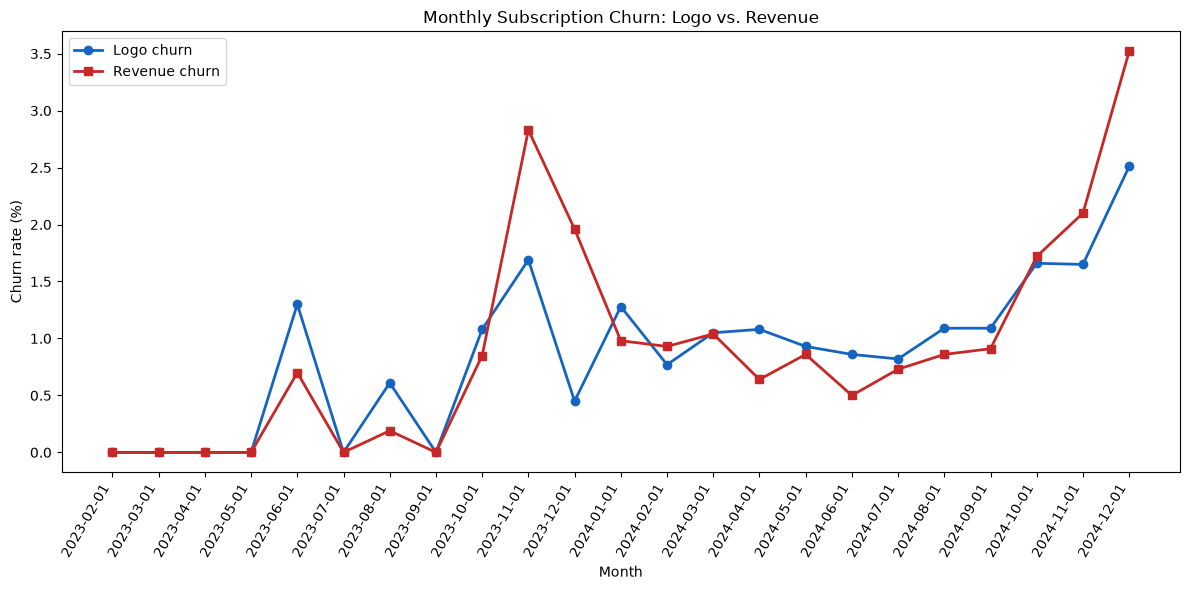

In [31]:
df_churn_monthly = df_churn_monthly.dropna()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_churn_monthly['month_start'], df_churn_monthly['logo_churn_pct'],
        marker='o', linewidth=2, color='#1565C0', label='Logo churn')
ax.plot(df_churn_monthly['month_start'], df_churn_monthly['revenue_churn_pct'],
        marker='s', linewidth=2, color='#C62828', label='Revenue churn')
ax.set_title('Monthly Subscription Churn: Logo vs. Revenue')
ax.set_xlabel('Month')
ax.set_ylabel('Churn rate (%)')
ax.legend()
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig('reports/assets/churn_logo_vs_revenue.png', dpi=150, bbox_inches='tight')

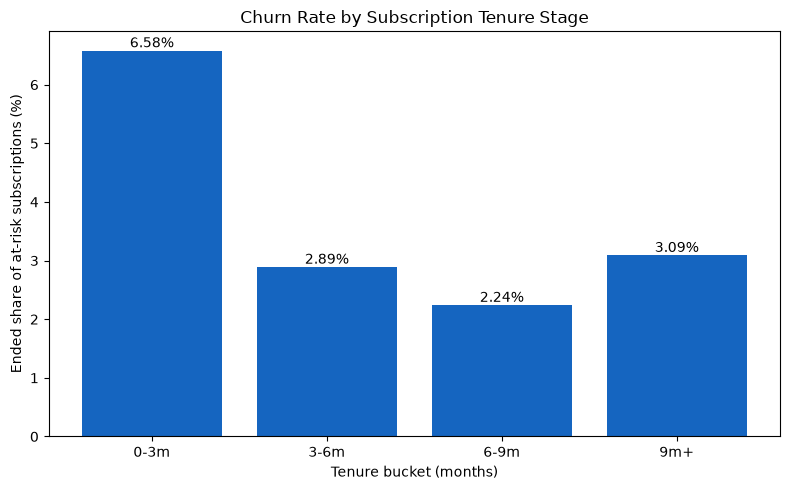

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(df_tenure['bucket'].str[2:], df_tenure['churn_pct'], color='#1565C0')
ax.bar_label(bars, fmt='%.2f%%')
ax.set_title('Churn Rate by Subscription Tenure Stage')
ax.set_xlabel('Tenure bucket (months)')
ax.set_ylabel('Ended share of at-risk subscriptions (%)')
plt.tight_layout()
plt.savefig('reports/assets/churn_by_tenure.png', dpi=150, bbox_inches='tight')

**Findings**
- 2024-06: logo churn 0.86%, revenue churn 0.50% (11 of 1,279 subscriptions). Most months sit at 0.5-1.7%; churn rises in Q4 2024 (2024-12: 2.51% logo, 3.52% revenue).
- Net revenue churn is negative in all 24 months: expansion outweighs losses. Gross churn is mostly below 1% (2024-12: 1.58%).
- Subscription-level churn is higher than account-level gross churn because other subscriptions on the same account offset the loss.
- The first 90 days are the riskiest: 6.58% / 2.89% / 2.24% / 3.09% (0-3m / 3-6m / 6-9m / 9m+). The 9m+ bucket is open-ended, so buckets are not directly comparable.

## 6. Cohort Retention

### 6.1 Cohort Groups

In [33]:
run_query("""
with cm as (
select
account_id,
min(month_start) as cohort_month
from account_month_mrr
where account_mrr > 0
group by account_id)

select
count(account_id) as cohort_count,
cohort_month
from cm
group by cohort_month
""")

,cohort_count,cohort_month
0,2,2023-01-01
1,7,2023-02-01
2,10,2023-03-01
3,15,2023-04-01
4,13,2023-05-01
5,18,2023-06-01
6,15,2023-07-01
7,25,2023-08-01
8,14,2023-09-01
9,18,2023-10-01


In [34]:
df_nrr = run_query("""
with cm as (
select
account_id,
min(month_start) as cohort_month
from account_month_mrr
where account_mrr > 0
group by account_id),

ms as (
select
a.account_id,
a.account_mrr,
c.cohort_month,
((cast(strftime('%Y', a.month_start) as integer) - cast(strftime('%Y', c.cohort_month) as integer)) * 12 
+ cast(strftime('%m', a.month_start) as integer) - cast(strftime('%m', c.cohort_month) as integer)) as months_since
from account_month_mrr a
join cm c on a.account_id = c.account_id),

matrix as(
select 
sum(account_mrr) as cohort_mrr,
cohort_month,
months_since
from ms
where months_since >= 0
group by cohort_month , months_since
),

base as (
select
cohort_month,
cohort_mrr as base_mrr
from matrix
where months_since = 0
)
select
    m.cohort_month,
    m.months_since,
    m.cohort_mrr,
    b.base_mrr,
    round(100.0 * m.cohort_mrr / b.base_mrr, 2) as nrr_pct
from matrix m
join base b on m.cohort_month = b.cohort_month
order by m.cohort_month, m.months_since
""")

In [35]:
df_grr = run_query("""
with cm as (
select
account_id,
min(month_start) as cohort_month
from account_month_mrr
where account_mrr > 0
group by account_id),

ms as (
select
a.account_id,
a.account_mrr,
c.cohort_month,
((cast(strftime('%Y', a.month_start) as integer) - cast(strftime('%Y', c.cohort_month) as integer)) * 12 
+ cast(strftime('%m', a.month_start) as integer) - cast(strftime('%m', c.cohort_month) as integer)) as months_since
from account_month_mrr a
join cm c on a.account_id = c.account_id),

grr_base as (
select
account_id,
cohort_month,
account_mrr as base_mrr
from ms
where months_since = 0
),

cap as (
select
sum(min(m.account_mrr, g.base_mrr)) as capped_mrr,
m.cohort_month,
m.months_since
from ms m 
join grr_base g on g.account_id = m.account_id
where months_since >= 0
group by m.cohort_month, m.months_since),

cohort_base as (
select
capped_mrr as base_mrr,
cohort_month
from cap
where  months_since = 0)


select
c.capped_mrr,
c.cohort_month,
c.months_since,
b.base_mrr,
round(100.0 * c.capped_mrr / b.base_mrr, 2) as grr_pct
from cap c
join cohort_base b on b.cohort_month = c.cohort_month
order by c.cohort_month, c.months_since
""")

In [36]:
run_query("""
with cm as (
select
account_id,
min(month_start) as cohort_month
from account_month_mrr
where account_mrr > 0
group by account_id),

ms as (
select
a.account_id,
a.account_mrr,
c.cohort_month,
((cast(strftime('%Y', a.month_start) as integer) - cast(strftime('%Y', c.cohort_month) as integer)) * 12 
+ cast(strftime('%m', a.month_start) as integer) - cast(strftime('%m', c.cohort_month) as integer)) as months_since
from account_month_mrr a
join cm c on a.account_id = c.account_id),

grr_base as (
select
account_id,
cohort_month,
account_mrr as base_mrr
from ms
where months_since = 0
),

cap as (
select
sum(min(m.account_mrr, g.base_mrr)) as capped_mrr,
m.cohort_month,
m.months_since
from ms m 
join grr_base g on g.account_id = m.account_id
where months_since >= 0
group by m.cohort_month, m.months_since),

cohort_base as (
select
capped_mrr as base_mrr,
cohort_month
from cap
where  months_since = 0),

grr_matrix_check as( 
select
c.capped_mrr,
c.cohort_month,
c.months_since,
b.base_mrr,
round(100.0 * c.capped_mrr / b.base_mrr, 2) as grr_pct
from cap c
join cohort_base b on b.cohort_month = c.cohort_month
order by c.cohort_month, c.months_since)

select
count(*)
from grr_matrix_check
where grr_pct < 90
""")

,count(*)
0,4


### 6.2 NRR and GRR Matrices

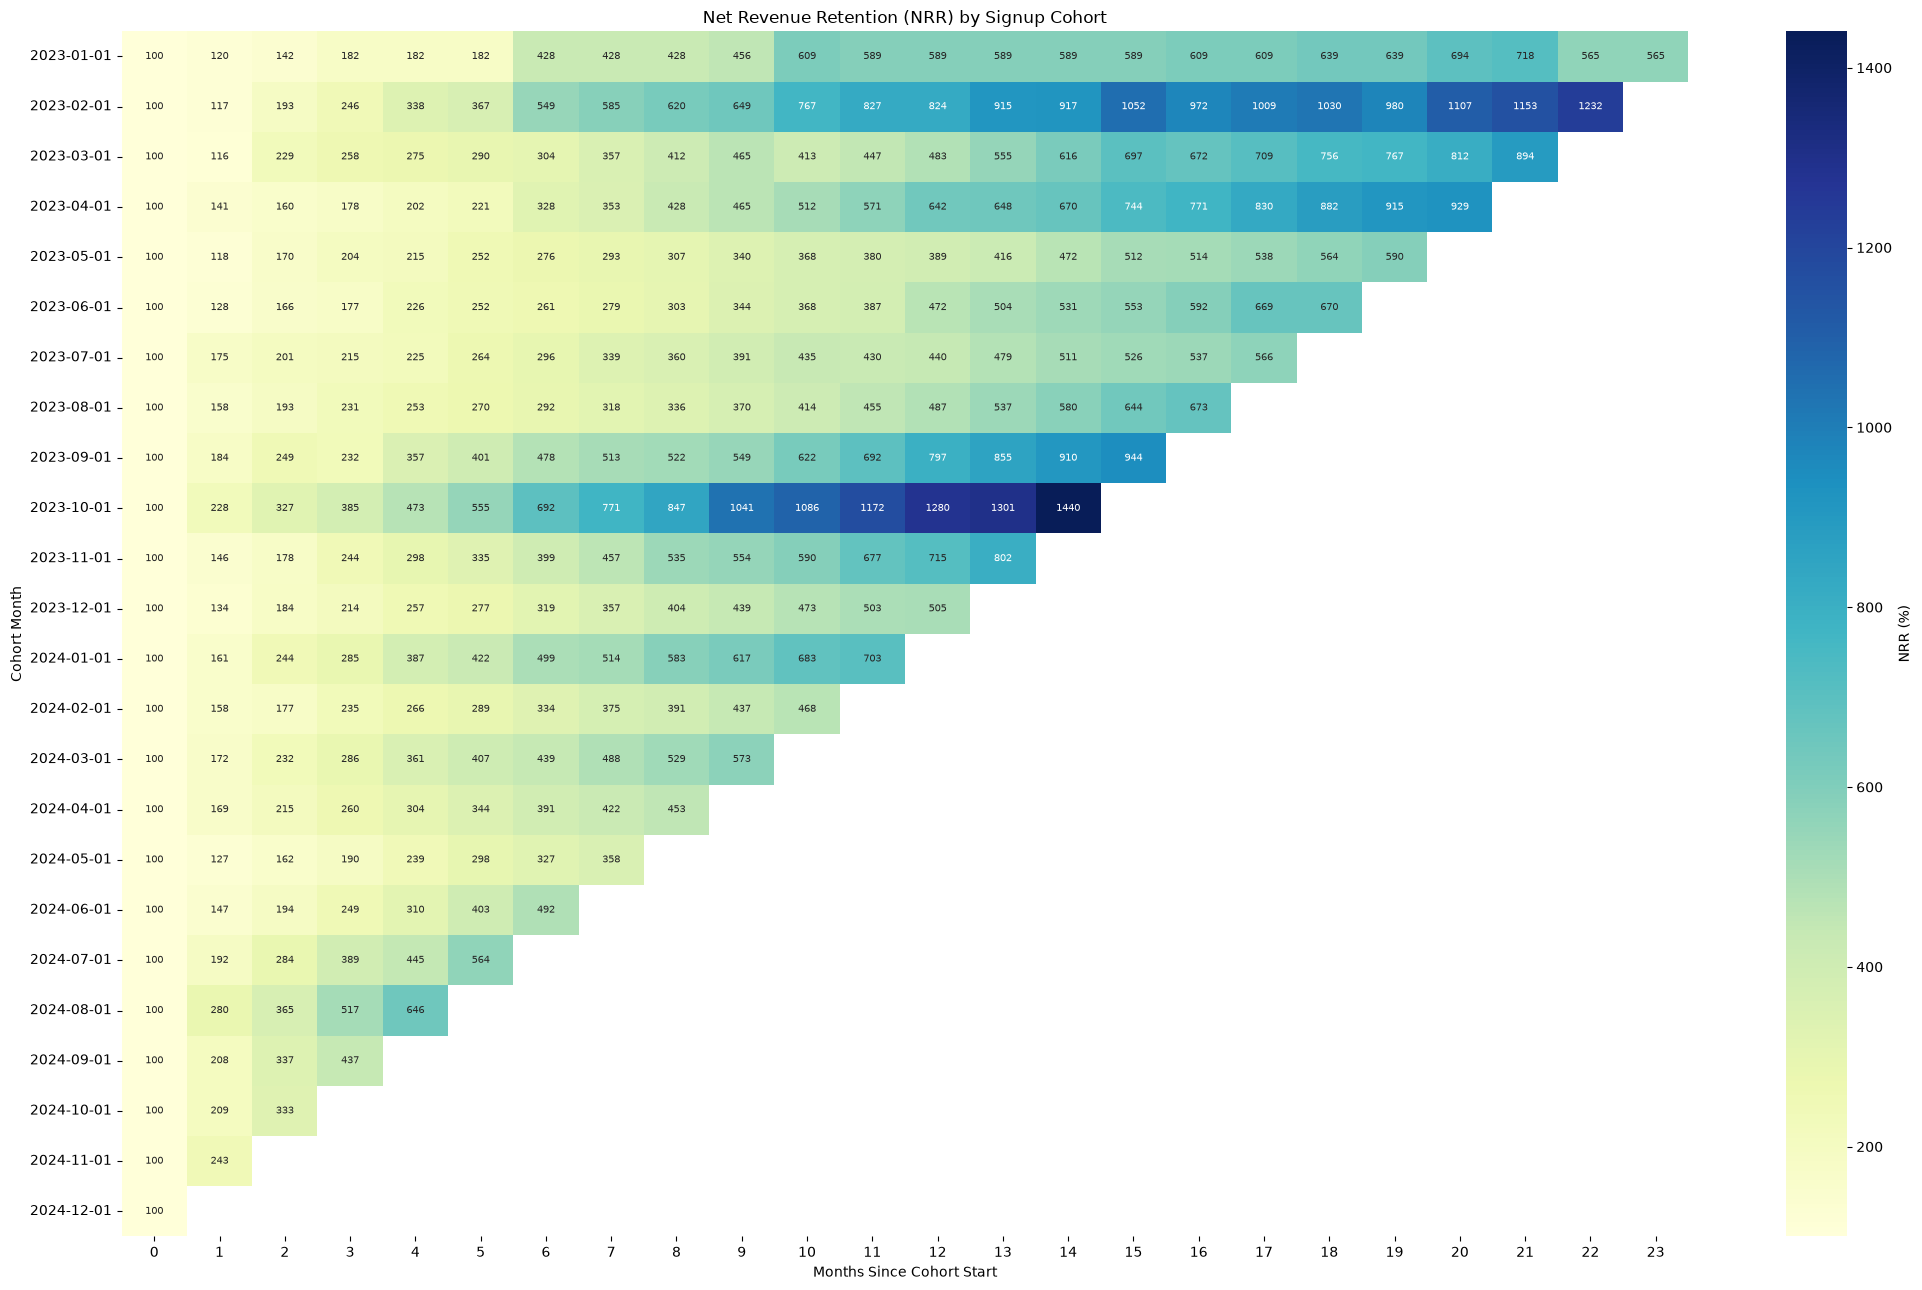

In [37]:
nrr_matrix = df_nrr.pivot(index="cohort_month", columns="months_since", values="nrr_pct")
fig, ax = plt.subplots(figsize=(21, 13))

sns.heatmap(
    nrr_matrix,
    annot=True,
    fmt=".0f",
    annot_kws={"size": 7},
    cmap="YlGnBu",
    cbar_kws={"label": "NRR (%)"},
)
ax.set_title("Net Revenue Retention (NRR) by Signup Cohort")
ax.set_xlabel("Months Since Cohort Start")
ax.set_ylabel("Cohort Month")
plt.tight_layout()
plt.savefig('reports/assets/nrr_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

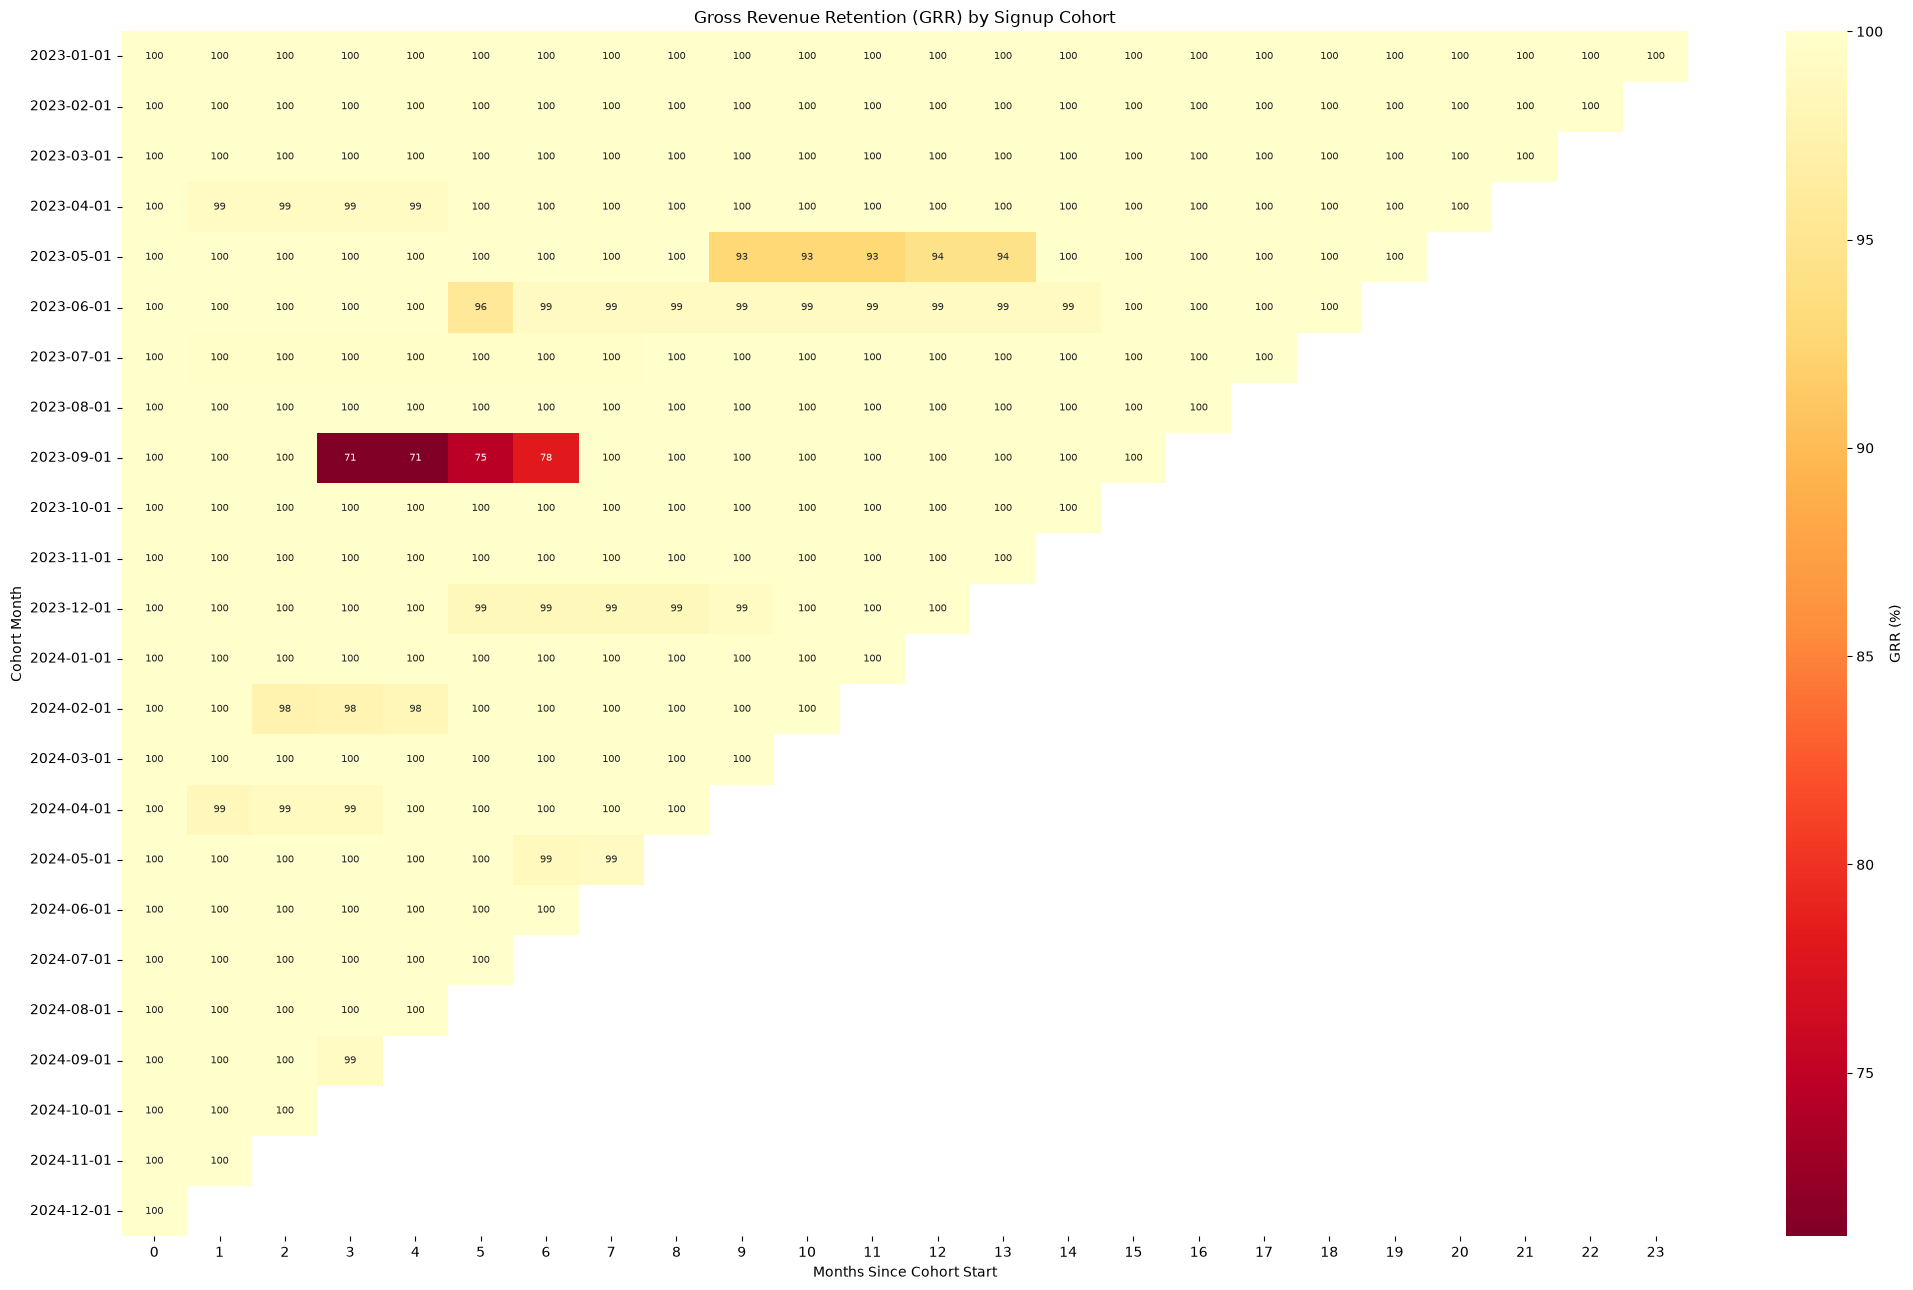

In [38]:
grr_matrix = df_grr.pivot(index="cohort_month", columns="months_since", values="grr_pct")
fig, ax = plt.subplots(figsize=(21, 13))

sns.heatmap(
    grr_matrix,
    annot=True,
    fmt=".0f",
    annot_kws={"size": 7},
    cmap="YlOrRd_r",
    cbar_kws={"label": "GRR (%)"},
)
ax.set_title("Gross Revenue Retention (GRR) by Signup Cohort")
ax.set_xlabel("Months Since Cohort Start")
ax.set_ylabel("Cohort Month")
plt.tight_layout()
plt.savefig('reports/assets/grr_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Findings**
- 500 accounts in 24 monthly cohorts. Early cohorts are very small (2023-01: 2 accounts), so their rates are noisy.
- NRR reaches 1,449% for the 2023-10 cohort at month 14, an outlier driven by expansion.
- GRR stays between 71.07% and 100%. The minimum comes from the single churn event (-12,736) in the 2023-09 cohort.
- GRR is capped per account, so it is not strictly decreasing.

## 7. Segmentation and LTV

### 7.1 ARPU by Plan (2024-06)

Check: plan MRR sums to 3,854,007 across 1,470 paid subscriptions.

In [39]:
run_query("""
select
plan_tier,
count(*) as paid_subs,
sum(mrr_amount) as plan_mrr,
round(1.0 * sum(mrr_amount) / count(*), 0) as arpu_per_sub,
round(100.0 * sum(mrr_amount) / sum(sum(mrr_amount)) over (), 1) as mrr_share_pct
from subscriptions
where is_trial = 0
and start_date <= '2024-06-30'
and (end_date is null or end_date >= '2024-06-01')
group by 1
order by plan_mrr desc
""")

,plan_tier,paid_subs,plan_mrr,arpu_per_sub,mrr_share_pct
0,Enterprise,490,2890674,5899.0,75.0
1,Pro,499,708638,1420.0,18.4
2,Basic,481,254695,530.0,6.6


**Findings**
- ARPU per subscription: Enterprise 5,899 / Pro 1,420 / Basic 530.
- Enterprise generates 75% of MRR.
- Account-level ARPU double counts accounts across plans (755 > 500), so subscription-level ARPU is the main metric.

### 7.2 LTV by Plan

In [40]:
df_ltv_plan = run_query("""
with recursive months as (
    select '2024-01-01' as month_start
    union all
    select date(month_start, '+1 month')
    from months
    where month_start < '2024-12-01'
),
subs as (
    select
        m.month_start,
        s.subscription_id,
        s.plan_tier,
        s.mrr_amount,
        s.end_date
    from months m
    left join subscriptions s
        on s.is_trial = 0
        and s.start_date <= m.month_start
        and (s.end_date is null or s.end_date >= m.month_start)
),
monthly as (
    select
        month_start,
        plan_tier,
        count(subscription_id) as paid_subs,
        sum(case when end_date < date(month_start, '+1 month') then 1 else 0 end) as ended_subs,
        1.0 * sum(mrr_amount) / count(subscription_id) as arpu_per_sub
    from subs
    where plan_tier is not null
    group by month_start, plan_tier
),
plan_stats as (
    select
        plan_tier,
        sum(ended_subs) as ended_subs,
        avg(arpu_per_sub) as avg_arpu_2024,
        100.0 * sum(ended_subs) / sum(paid_subs) as weighted_churn_2024,
        count(*) as months
    from monthly
    group by plan_tier
)
select
    plan_tier,
    ended_subs,
    round(avg_arpu_2024, 2) as avg_arpu_2024,
    round(weighted_churn_2024, 2) as weighted_churn_2024,
    round(100.0 / weighted_churn_2024, 1) as lifetime_months,
    round(avg_arpu_2024 * 100.0 / weighted_churn_2024) as ltv,
    months
from plan_stats
order by ltv desc
""")

### 7.3 Upgrade and Downgrade Flags

In [41]:
run_query("""
select
plan_tier,
round( 100.0 * sum(upgrade_flag)/ count(*),2 ) as upgrade_pct,
round( 100.0 * sum(downgrade_flag) /count(*), 2) as downgrade_pct,
round( 100.0 * sum(churn_flag) / count(*), 2) as churn_pct
from subscriptions
where is_trial = 0
group by plan_tier
""")

,plan_tier,upgrade_pct,downgrade_pct,churn_pct
0,Basic,9.07,3.83,9.44
1,Enterprise,11.03,4.21,10.07
2,Pro,11.86,5.30,9.46


**Findings**
- Upgrade flags are set on 9-12% of paid subscriptions and downgrade flags on 4-5%, with similar rates across plans.
- The flags do not follow plan order (e.g. upgrades appear on Enterprise, downgrades on Basic). They are indicators, not direction, so a transition matrix or monthly trend cannot be built.

### 7.4 LTV by Industry, Country and Referral Source

In [42]:
df_ltv_industry = run_query("""
with recursive months as (
    select '2024-01-01' as month_start
    union all
    select date(month_start, '+1 month')
    from months
    where month_start < '2024-12-01'
),
subs as (
    select
        m.month_start,
        s.subscription_id,
        a.industry,
        s.mrr_amount,
        s.end_date
    from months m
    left join subscriptions s
        on s.is_trial = 0
        and s.start_date <= m.month_start
        and (s.end_date is null or s.end_date >= m.month_start)
    left join accounts a
        on a.account_id = s.account_id
),
monthly as (
    select
        month_start,
        industry,
        count(subscription_id) as paid_subs,
        sum(case when end_date < date(month_start, '+1 month') then 1 else 0 end) as ended_subs,
        1.0 * sum(mrr_amount) / count(subscription_id) as arpu_per_sub
    from subs
    where industry is not null
    group by month_start, industry
),
segment_stats as (
    select
        industry,
        sum(ended_subs) as ended_subs,
        avg(arpu_per_sub) as avg_arpu_2024,
        100.0 * sum(ended_subs) / sum(paid_subs) as weighted_churn_2024,
        avg(paid_subs) as avg_paid_subs,
        count(*) as months
    from monthly
    group by industry
)
select
    industry,
    ended_subs,
    round(avg_arpu_2024, 2) as avg_arpu_2024,
    round(weighted_churn_2024, 2) as weighted_churn_2024,
    round(100.0 / weighted_churn_2024, 1) as lifetime_months,
    round(avg_arpu_2024 * 100.0 / weighted_churn_2024) as ltv,
    round(avg_paid_subs) as avg_paid_subs,
    months
from segment_stats
order by ltv desc
""")

In [43]:
df_ltv_country = run_query("""
with recursive months as (
    select '2024-01-01' as month_start
    union all
    select date(month_start, '+1 month')
    from months
    where month_start < '2024-12-01'
),
subs as (
    select
        m.month_start,
        s.subscription_id,
        a.country,
        s.mrr_amount,
        s.end_date
    from months m
    left join subscriptions s
        on s.is_trial = 0
        and s.start_date <= m.month_start
        and (s.end_date is null or s.end_date >= m.month_start)
    left join accounts a
        on a.account_id = s.account_id
),
monthly as (
    select
        month_start,
        country,
        count(subscription_id) as paid_subs,
        sum(case when end_date < date(month_start, '+1 month') then 1 else 0 end) as ended_subs,
        1.0 * sum(mrr_amount) / count(subscription_id) as arpu_per_sub
    from subs
    where country is not null
    group by month_start, country
),
segment_stats as (
    select
        country,
        sum(ended_subs) as ended_subs,
        avg(arpu_per_sub) as avg_arpu_2024,
        100.0 * sum(ended_subs) / sum(paid_subs) as weighted_churn_2024,
        avg(paid_subs) as avg_paid_subs,
        count(*) as months
    from monthly
    group by country
)
select
    country,
    ended_subs,
    round(avg_arpu_2024, 2) as avg_arpu_2024,
    round(weighted_churn_2024, 2) as weighted_churn_2024,
    round(100.0 / weighted_churn_2024, 1) as lifetime_months,
    round(avg_arpu_2024 * 100.0 / weighted_churn_2024) as ltv,
    round(avg_paid_subs) as avg_paid_subs,
    months
from segment_stats
order by ltv desc
""")

In [44]:
df_ltv_referral = run_query("""
with recursive months as (
    select '2024-01-01' as month_start
    union all
    select date(month_start, '+1 month')
    from months
    where month_start < '2024-12-01'
),
subs as (
    select
        m.month_start,
        s.subscription_id,
        a.referral_source,
        s.mrr_amount,
        s.end_date
    from months m
    left join subscriptions s
        on s.is_trial = 0
        and s.start_date <= m.month_start
        and (s.end_date is null or s.end_date >= m.month_start)
    left join accounts a
        on a.account_id = s.account_id
),
monthly as (
    select
        month_start,
        referral_source,
        count(subscription_id) as paid_subs,
        sum(case when end_date < date(month_start, '+1 month') then 1 else 0 end) as ended_subs,
        1.0 * sum(mrr_amount) / count(subscription_id) as arpu_per_sub
    from subs
    where referral_source is not null
    group by month_start, referral_source
),
segment_stats as (
    select
        referral_source,
        sum(ended_subs) as ended_subs,
        avg(arpu_per_sub) as avg_arpu_2024,
        100.0 * sum(ended_subs) / sum(paid_subs) as weighted_churn_2024,
        avg(paid_subs) as avg_paid_subs,
        count(*) as months
    from monthly
    group by referral_source
)
select
    referral_source,
    ended_subs,
    round(avg_arpu_2024, 2) as avg_arpu_2024,
    round(weighted_churn_2024, 2) as weighted_churn_2024,
    round(100.0 / weighted_churn_2024, 1) as lifetime_months,
    round(avg_arpu_2024 * 100.0 / weighted_churn_2024) as ltv,
    round(avg_paid_subs) as avg_paid_subs,
    months
from segment_stats
order by ltv desc
""")

**Check:** ended subscriptions sum to 268 in every segmentation.

In [45]:
segment_frames = {
    'plan': df_ltv_plan,
    'industry': df_ltv_industry,
    'country': df_ltv_country,
    'referral_source': df_ltv_referral,
}

for name, df in segment_frames.items():
    total_ended = df['ended_subs'].sum()
    assert total_ended == 268, f'{name}: ended_subs total is {total_ended}, expected 268'
    print(f'{name}: ended_subs total = {total_ended}')
    display(df)

plan: ended_subs total = 268


,plan_tier,ended_subs,avg_arpu_2024,weighted_churn_2024,lifetime_months,ltv,months
0,Enterprise,99,5643.42,1.56,63.9,360723.0,12
1,Pro,83,1441.36,1.33,75.0,108154.0,12
2,Basic,86,534.16,1.40,71.6,38267.0,12


industry: ended_subs total = 268


,industry,ended_subs,avg_arpu_2024,weighted_churn_2024,lifetime_months,ltv,avg_paid_subs,months
0,FinTech,56,2656.06,1.32,75.9,201719.0,354.0,12
1,HealthTech,51,2594.49,1.36,73.4,190314.0,312.0,12
2,Cybersecurity,51,2564.44,1.44,69.6,178556.0,296.0,12
3,EdTech,38,2445.56,1.41,71.1,173828.0,225.0,12
4,DevTools,72,2409.87,1.61,62.1,149646.0,373.0,12


country: ended_subs total = 268


,country,ended_subs,avg_arpu_2024,weighted_churn_2024,lifetime_months,ltv,avg_paid_subs,months
0,IN,17,2599.06,0.76,131.1,340629.0,186.0,12
1,CA,11,2959.45,1.36,73.6,217923.0,68.0,12
2,US,153,2581.71,1.44,69.3,179015.0,884.0,12
3,DE,13,2208.95,1.35,74.3,164142.0,81.0,12
4,AU,22,2738.67,1.90,52.6,144154.0,97.0,12
5,FR,15,2722.72,2.01,49.7,135229.0,62.0,12
6,UK,37,2119.76,1.68,59.5,126097.0,183.0,12


referral_source: ended_subs total = 268


,referral_source,ended_subs,avg_arpu_2024,weighted_churn_2024,lifetime_months,ltv,avg_paid_subs,months
0,ads,47,2629.66,1.17,85.6,225143.0,335.0,12
1,other,46,2434.83,1.23,81.2,197645.0,311.0,12
2,partner,50,2455.87,1.40,71.5,175693.0,298.0,12
3,event,50,2283.38,1.47,67.9,155133.0,283.0,12
4,organic,75,2858.90,1.88,53.1,151903.0,332.0,12


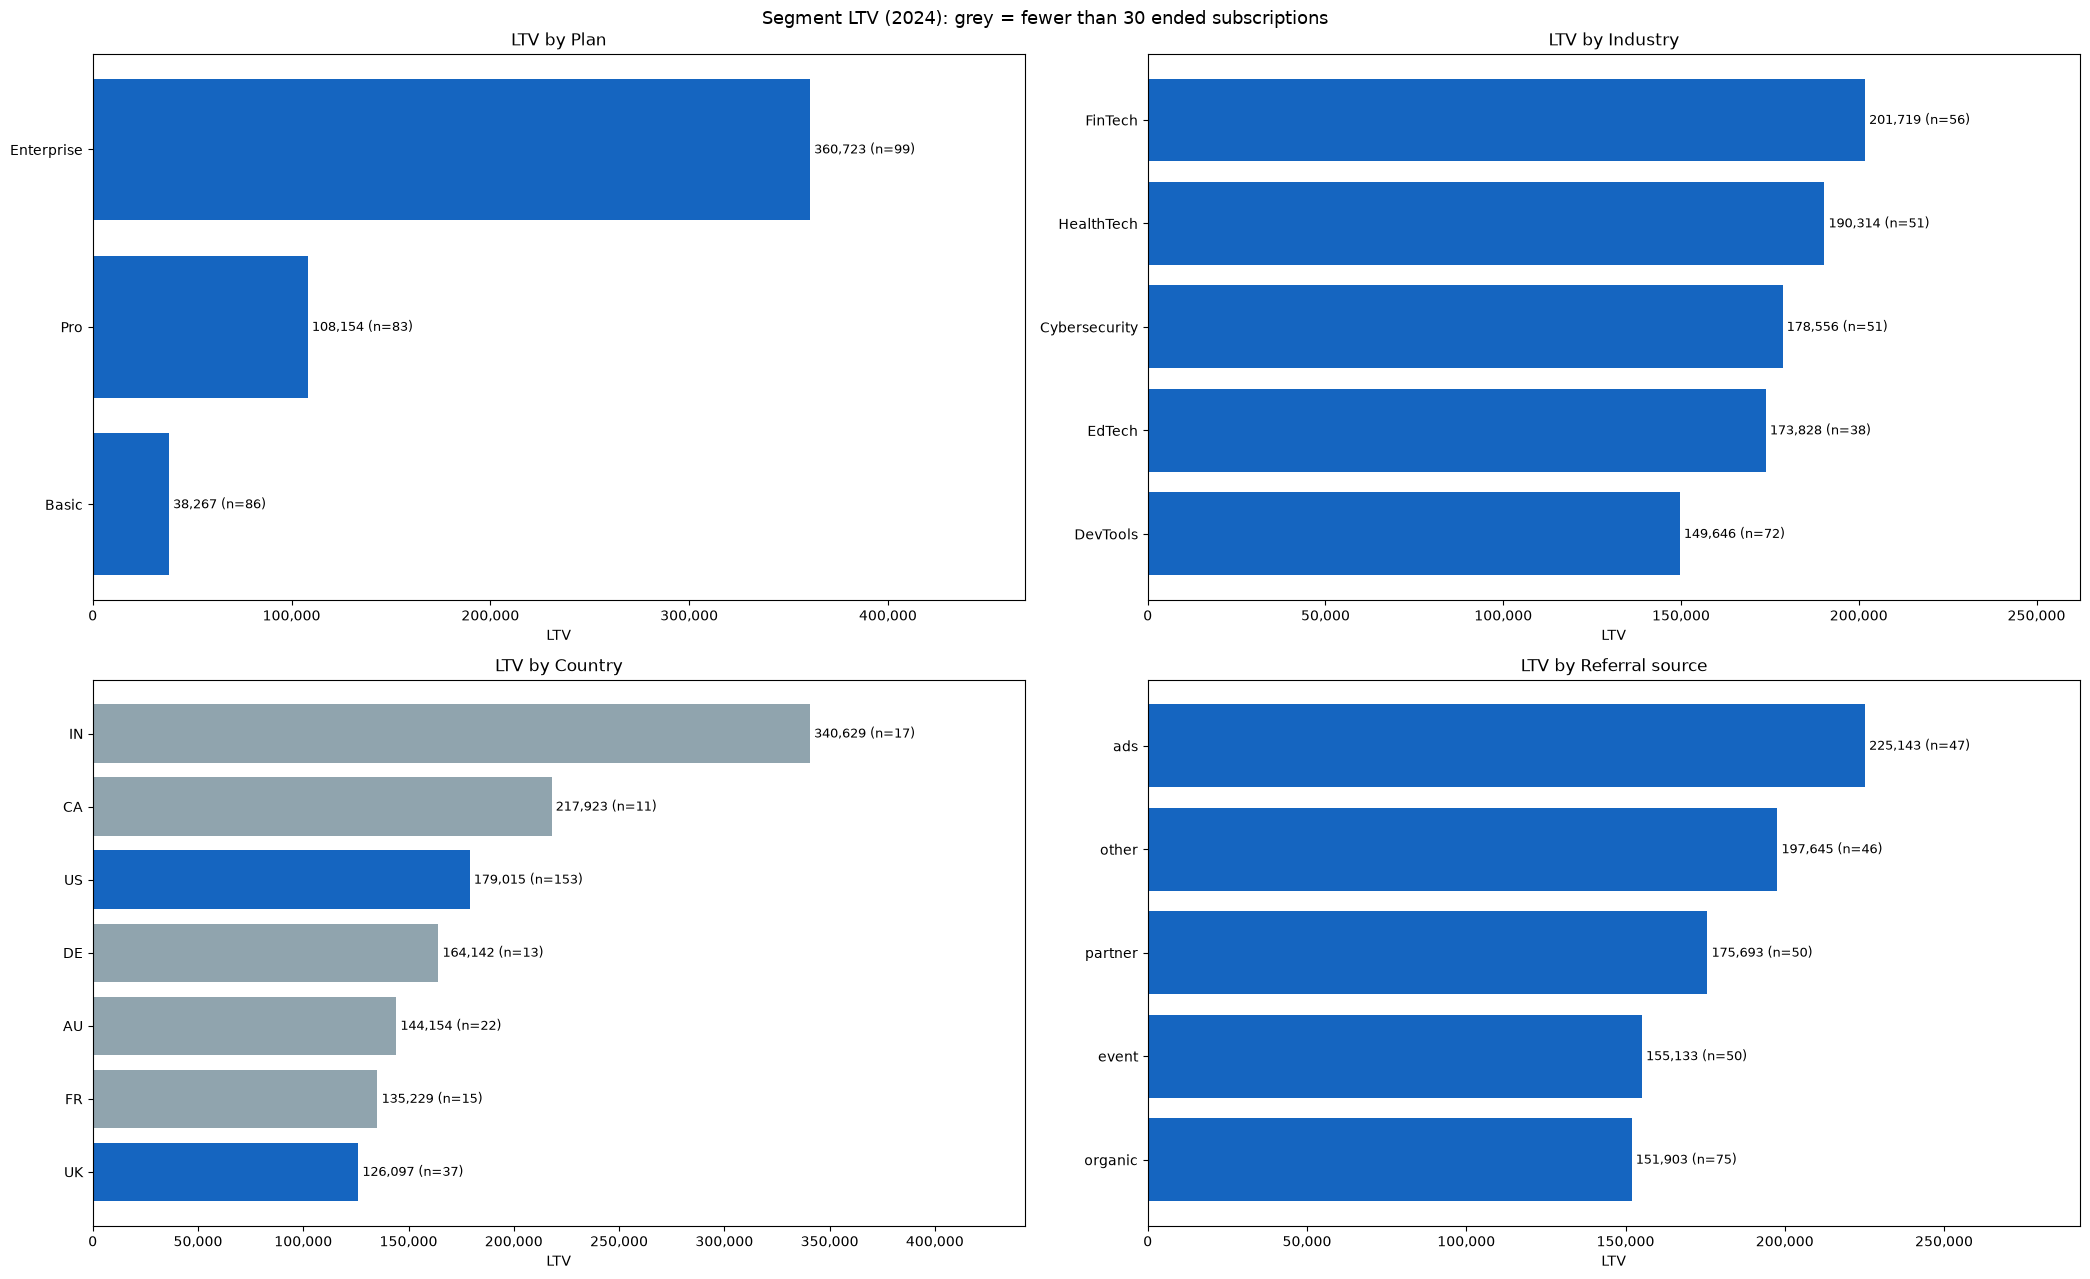

In [46]:
from matplotlib.ticker import FuncFormatter

ltv_frames = {
    'Plan': (df_ltv_plan, 'plan_tier'),
    'Industry': (df_ltv_industry, 'industry'),
    'Country': (df_ltv_country, 'country'),
    'Referral source': (df_ltv_referral, 'referral_source'),
}

fig, axes = plt.subplots(2, 2, figsize=(21, 13))
for ax, (title, (df, col)) in zip(axes.flat, ltv_frames.items()):
    df = df.sort_values('ltv')
    colors = ['#90A4AE' if n < 30 else '#1565C0' for n in df['ended_subs']]
    bars = ax.barh(df[col], df['ltv'], color=colors)
    labels = [f'{v:,.0f} (n={n})' for v, n in zip(df['ltv'], df['ended_subs'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=9)
    ax.set_title(f'LTV by {title}')
    ax.set_xlabel('LTV')
    ax.set_xlim(0, df['ltv'].max() * 1.3)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
fig.suptitle('Segment LTV (2024): grey = fewer than 30 ended subscriptions', fontsize=13)
plt.tight_layout()
plt.savefig('reports/assets/segment_ltv.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.5 Segment LTV Summary (2024, weighted monthly churn)

| Segment | Top | LTV | Bottom | LTV | Ended subs |
|---|---|---|---|---|---|
| Plan | Enterprise | 360,723 | Basic | 38,267 | 268 |
| Industry | FinTech | 201,719 | DevTools | 149,646 | 268 |
| Country | IN | 340,629 | UK | 126,097 | 268 |
| Referral source | ads | 225,143 | organic | 151,903 | 268 |

**Findings**
- Enterprise is the most profitable segment (LTV 360,723, 99 ended subscriptions). Its churn is the highest of the three plans, but its ARPU is about 4x Pro's.
- IN ranks first by country, but the result rests on only 17 ended subscriptions. 5 of 7 countries have fewer than 30.
- Industry rankings are close to each other and within noise.
- Organic leads on ARPU (2,859) but ranks last on LTV because of 1.88% monthly churn. Ads is the strongest acquisition channel.
- Lifetime estimates extend beyond the 24 months of data and are projections.

**Decision:** Enterprise plan is the most profitable segment; IN is a candidate to monitor; ads is the strongest acquisition channel.